In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data  = pd.read_csv('spam.csv', encoding='latin-1')

In [3]:
data.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
1115,ham,So lets make it saturday or monday as per conv...,NaN,NaN,NaN
5255,ham,Ok... Sweet dreams...,NaN,NaN,NaN
4146,ham,Pls help me tell sura that i'm expecting a bat...,NaN,NaN,NaN
1341,ham,Just chill for another 6hrs. If you could slee...,NaN,NaN,NaN
348,spam,Fancy a shag? I do.Interested? sextextuk.com t...,NaN,NaN,NaN


# Feature Engineering


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


## Data Cleaning


In [5]:
data.drop(["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"], axis=1, inplace=True)

In [6]:
data

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   v1      5572 non-null   str  
 1   v2      5572 non-null   str  
dtypes: str(2)
memory usage: 541.4 KB


In [8]:
# renaming the columns names
data.rename(columns={"v1": "target", "v2":"text"}, inplace=True)

In [9]:
data

,target,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [10]:
data["target"].value_counts()

target
ham     4825
spam     747
Name: count, dtype: int64

In [11]:
print(data["target"].unique())

<ArrowStringArray>
['ham', 'spam']
Length: 2, dtype: str


In [12]:
# data["target"] = data["target"].map({
#     "ham": 0,
#     "spam": 1
# })


# or i can go with label encoder
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data["target"] = le.fit_transform(data["target"])

In [13]:
data["target"].value_counts()

target
0    4825
1     747
Name: count, dtype: int64

In [14]:
# checking the null values
data.isnull().sum()

target    0
text      0
dtype: int64

In [15]:
#  checking the duplicate values
data.duplicated().sum()

np.int64(403)

In [16]:
# remove the duplicate values
data.drop_duplicates(inplace=True, keep="first")

In [17]:
data.duplicated().sum()

np.int64(0)

In [18]:
data.shape

(5169, 2)

# EDA (Exploratory Data Analysis)

In [19]:
data["target"].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

### Here, Clearly Visible that our dataset is properly imbalanced data

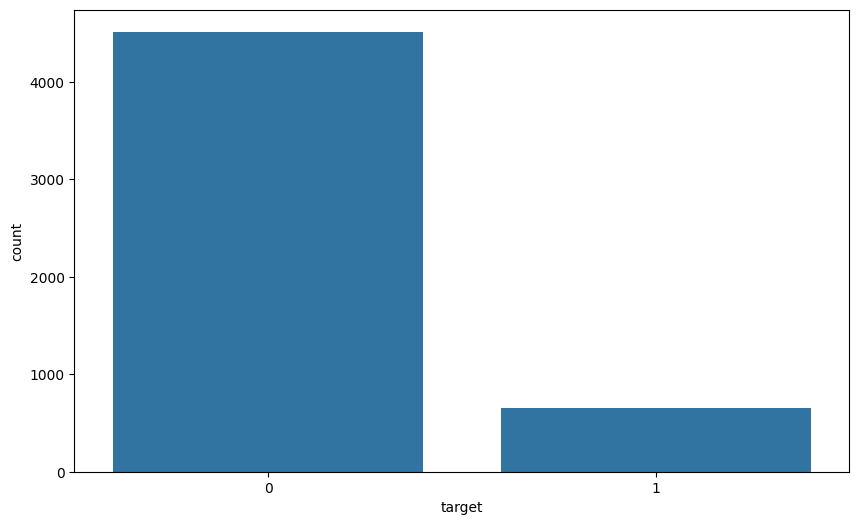

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(x="target", data=data)
plt.show()


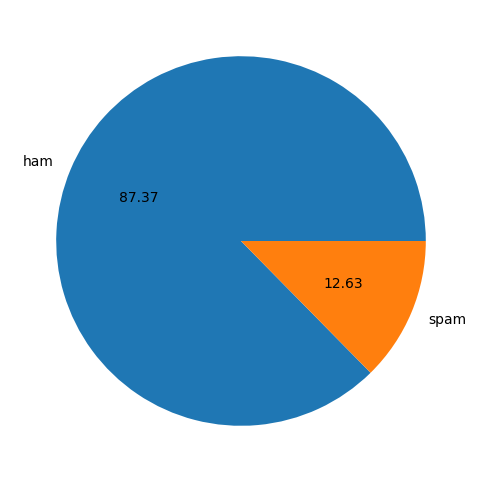

In [21]:
# pie chart
plt.figure(figsize=(10, 6))

plt.pie(data["target"].value_counts(), labels=["ham", "spam"], autopct="%0.2f")
plt.show()

### Check how much our data follow the normal distribution

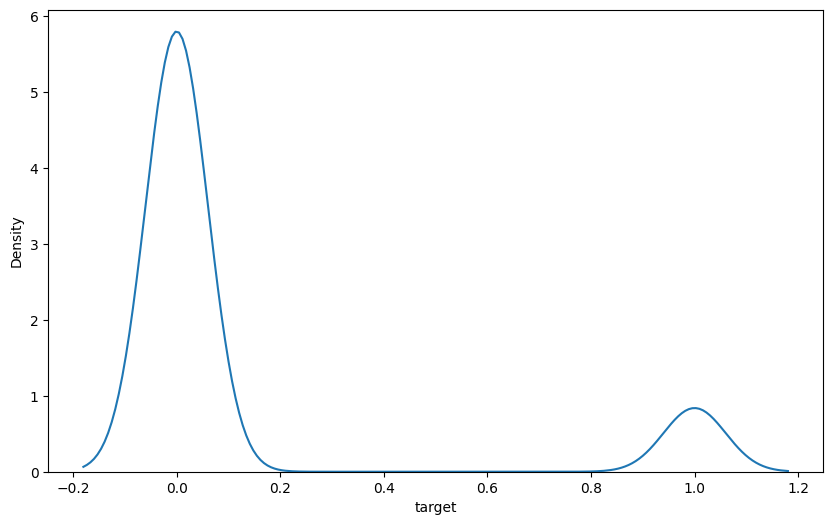

In [22]:
# checking the data is normally distributed or not
plt.figure(figsize=(10, 6))

sns.kdeplot(data["target"])
plt.show()

In [23]:
!pip install nltk


In [24]:
import nltk
nltk.download("punkt")
nltk.download("stopwords")
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/mohddanish/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mohddanish/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/mohddanish/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [25]:
# length of the each sentence in the data
data["num_characters"] = data["text"].apply(lambda x:len(x))
# data["text"].apply(len)

In [26]:
data

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161
5568,0,Will Ì_ b going to esplanade fr home?,37
5569,0,"Pity, * was in mood for that. So...any other s...",57
5570,0,The guy did some bitching but I acted like i'd...,125


In [27]:
# now breaking the text into words

# data["num_words"] = data["text"].apply(lambda x:len(x.split(" ")))
# or
data["num_words"] = data["text"].apply(lambda x:len(nltk.word_tokenize(x)))

In [28]:
data

,target,text,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15
...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35
5568,0,Will Ì_ b going to esplanade fr home?,37,9
5569,0,"Pity, * was in mood for that. So...any other s...",57,15
5570,0,The guy did some bitching but I acted like i'd...,125,27


In [29]:
# breaking the text into sentences
data["num_sentences"] = data["text"].apply(lambda x:len(nltk.sent_tokenize(x)))

In [30]:
data

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,0,The guy did some bitching but I acted like i'd...,125,27,1


In [31]:
nltk.sent_tokenize(data["text"][0])

['Go until jurong point, crazy..',
 'Available only in bugis n great world la e buffet... Cine there got amore wat...']

In [32]:
data[["num_characters", "num_words", "num_sentences"]].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [33]:
# spam - 1
# not spam -2

data[data["target"] == 0][
    ["num_characters", "num_words", "num_sentences"]
]

data[data["target"] == 0][
    ["num_characters", "num_words", "num_sentences"]
].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [34]:
data[data["target"] == 1][
    ["num_characters", "num_words", "num_sentences"]
]

data[data["target"] == 1][
    ["num_characters", "num_words", "num_sentences"]
].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


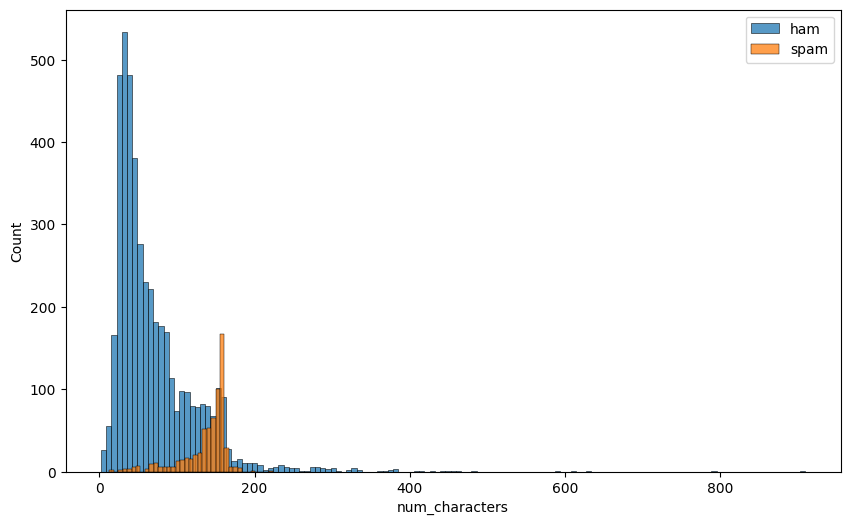

In [35]:
# ploting histogram of spam and ham

plt.figure(figsize=(10, 6))

sns.histplot(data[data["target"] == 0]["num_characters"], label="ham")
sns.histplot(data[data["target"] == 1]["num_characters"], label="spam")
plt.legend()
plt.show()

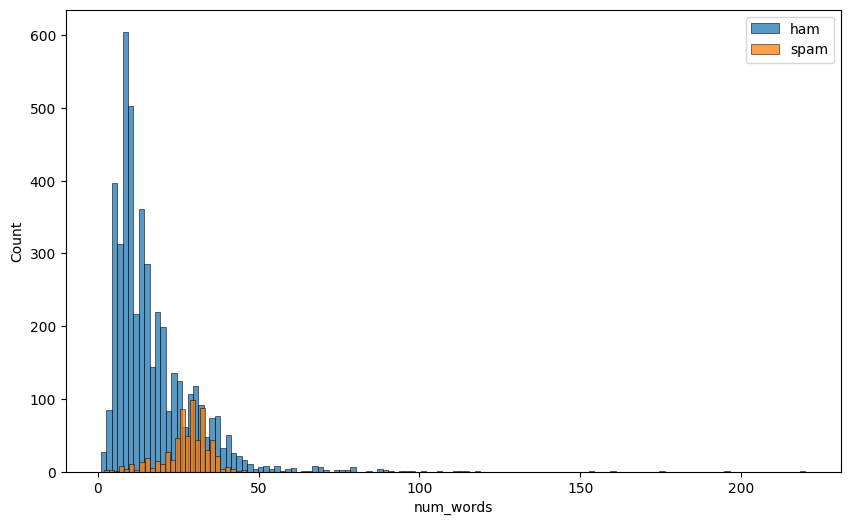

In [36]:
plt.figure(figsize=(10, 6))

sns.histplot(data[data["target"] == 0]["num_words"], label="ham")
sns.histplot(data[data["target"] == 1]["num_words"], label="spam")
plt.legend()
plt.show()

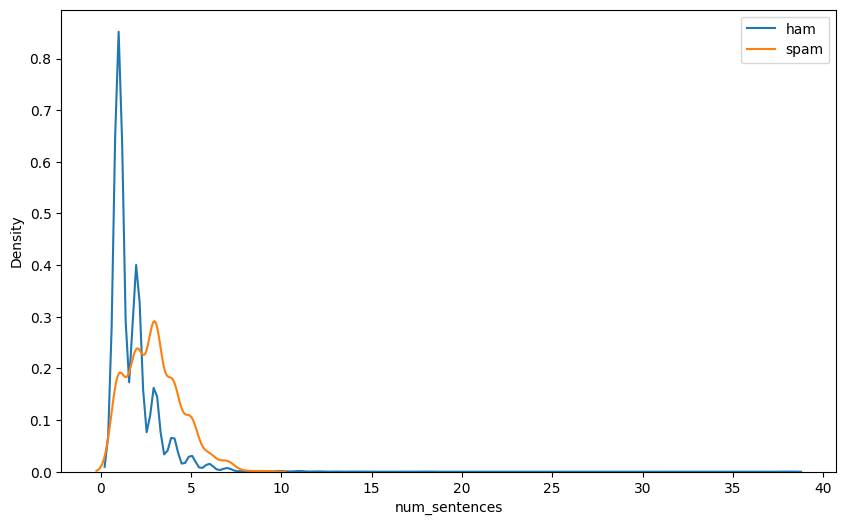

In [37]:
plt.figure(figsize=(10, 6))

sns.kdeplot(data[data["target"] == 0]["num_sentences"], label="ham")
sns.kdeplot(data[data["target"] == 1]["num_sentences"], label="spam")
plt.legend()
plt.show()

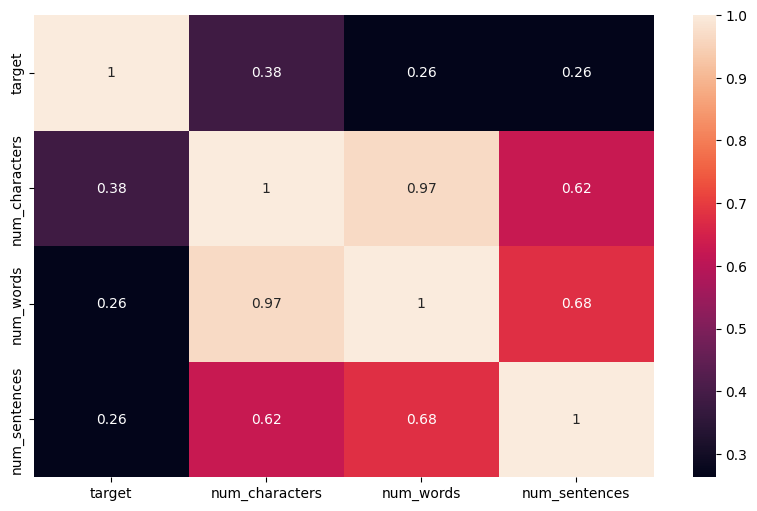

In [38]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    data.select_dtypes(include="number").corr(),
    annot=True
)

plt.show()

<Figure size 1000x600 with 0 Axes>

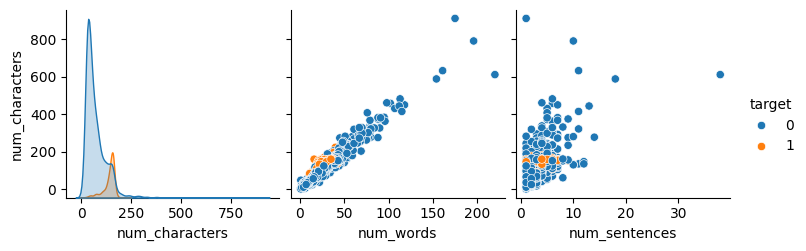

<Figure size 1000x600 with 0 Axes>

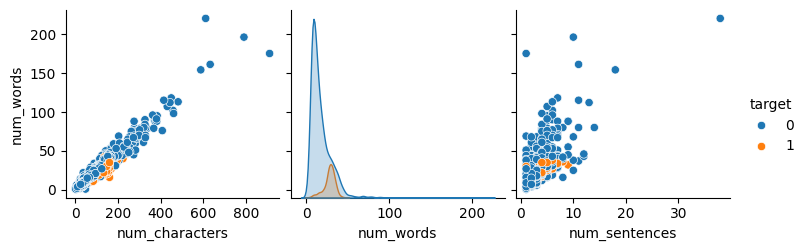

<Figure size 1000x600 with 0 Axes>

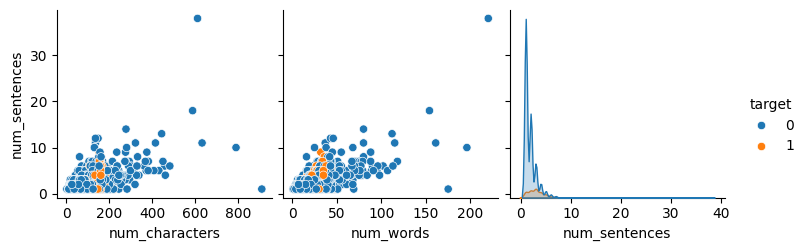

In [39]:
cols = ["num_characters", "num_words", "num_sentences"]
for col in cols:
    plt.figure(figsize=(10, 6))
    sns.pairplot(data, x_vars=cols, y_vars=col, hue="target")
    plt.show()

Data Processing
```
      . lower case
      . tokenization(breaking sentences into the words)
      . removing special characters(removing the special characters)
      . removing stop words and punctuation(stop word ->[are, is, the, I, am and etc], punctuation[, . ! @ # and etc])
      . stemming = Removing word endings.
      . lemmatization = Converting words into their meaningful dictionary base form.
```
      

In [40]:
data

,target,text,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,0,The guy did some bitching but I acted like i'd...,125,27,1


In [41]:
from nltk.corpus import stopwords
import string
import nltk

def DataPreprocessing(text):
    text = text.lower()
    text = nltk.word_tokenize(text)

    y = []

    # Removing special characters
    for i in text:
        if i.isalnum():
            y.append(i)
    
    text = y[:]
    y.clear()


    # Removing stop words and punctuations
    for i in text:
        if i not in stopwords.words("english") and i not in string.punctuation:
            y.append(i)

    text = y[:]
    y.clear()

    # stemming -> concept of stemming is to convert a word to its root word like "going" to "go", "gone"
    ps = nltk.PorterStemmer()
    for i in text:
        y.append(ps.stem(i))

    text = y[:]
    y.clear()
    
    return " ".join(text)


In [42]:
# passing actual data text to function
data["transformed_text"] = data["text"].apply(DataPreprocessing)

In [43]:
text = DataPreprocessing("Hello my name is Mohd Danish. Here We have the Special characters such as $, #, @, I loving to write the code and train the machine learning models")
print(text)

hello name mohd danish special charact love write code train machin learn model


In [44]:
data

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


In [45]:
array = [1,2,3,4,5,6]

# list comprehension
result = [x**2 for x in array]
print(result)

# map function with lambda function
result = list(map(lambda x: x**2, array))
print(result)

[1, 4, 9, 16, 25, 36]
[1, 4, 9, 16, 25, 36]


In [46]:
!pip install wordcloud

In [47]:
from wordcloud import WordCloud
wc = WordCloud(width=1000, height=1000, min_font_size=10, background_color="white")

In [48]:
# spam_wc = wc.generate(data[data["target"] == 1]["transformed_text"].sum())
spam_wc = wc.generate(data[data["target"] == 1]["transformed_text"].str.cat(sep=" "))

In [49]:
data[data["target"] == 1]["transformed_text"].sum()

'free entri 2 wkli comp win fa cup final tkt 21st may text fa 87121 receiv entri question std txt rate c appli 08452810075over18freemsg hey darl 3 week word back like fun still tb ok xxx std chg send rcvwinner valu network custom select receivea prize reward claim call claim code kl341 valid 12 hourmobil 11 month u r entitl updat latest colour mobil camera free call mobil updat co free 08002986030six chanc win cash 100 pound txt csh11 send cost 6day tsandc appli repli hl 4 infourgent 1 week free membership prize jackpot txt word claim 81010 c lccltd pobox 4403ldnw1a7rw18xxxmobilemovieclub use credit click wap link next txt messag click httpengland v macedonia dont miss news txt ur nation team 87077 eg england 87077 tri wale scotland poboxox36504w45wqthank subscript rington uk mobil charg pleas confirm repli ye repli charg07732584351 rodger burn msg tri call repli sm free nokia mobil free camcord pleas call 08000930705 deliveri tomorrowsm ac sptv new jersey devil detroit red wing play i

In [50]:
spam_wc

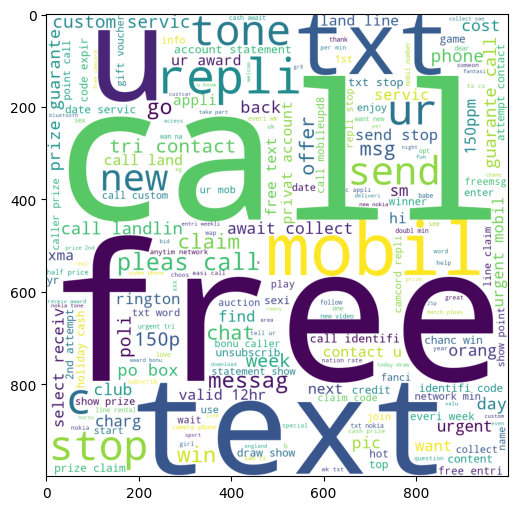

In [51]:
plt.figure(figsize=(10, 6))
plt.imshow(spam_wc)

In [52]:
not_spam_wc = wc.generate(data[data["target"] == 0]["transformed_text"].str.cat(sep=" "))

In [53]:
not_spam_wc

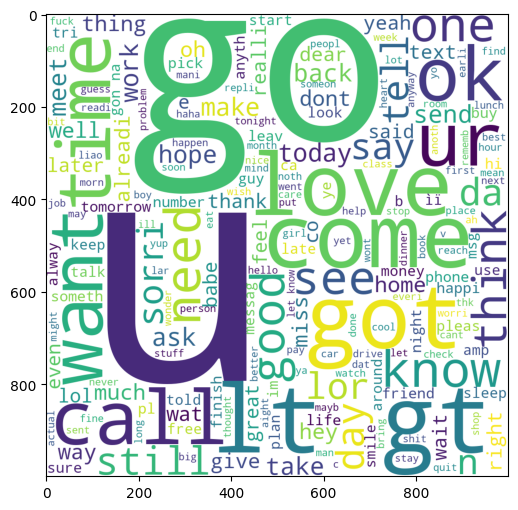

In [96]:
plt.figure(figsize=(10, 6))
plt.imshow(not_spam_wc)

In [99]:
# counting the top 30 word in the spam message or which word repeating the most

store = data[data["target"] == 1]["transformed_text"].str.split().explode().value_counts().head(30)
type(store)

pandas.Series

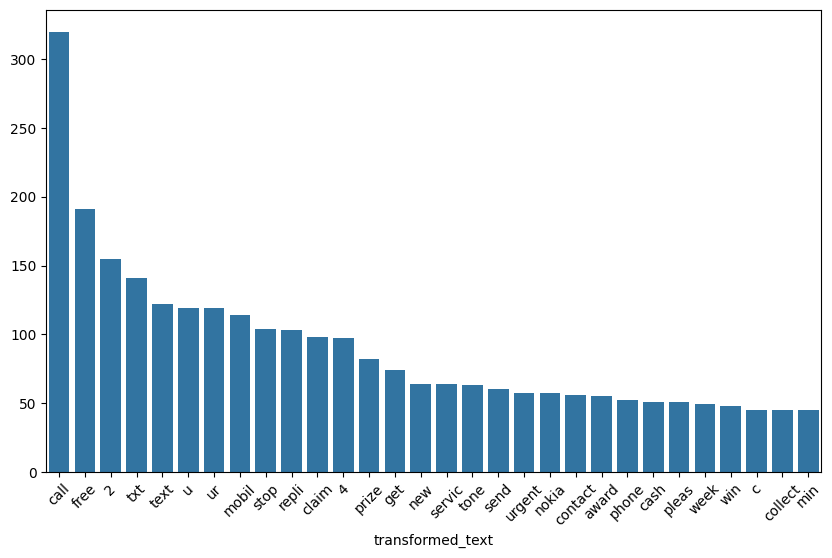

In [56]:
plt.figure(figsize=(10, 6))
sns.barplot(x=store.index, y=store.values)
plt.xticks(rotation=45)
plt.show()

In [101]:
spam_corpus = []

for message in data[data["target"] == 1]["transformed_text"].str.split():
    spam_corpus.append(" ".join(message))
spam_corpus = " ".join(spam_corpus)
spam_corpus

'free entri 2 wkli comp win fa cup final tkt 21st may text fa 87121 receiv entri question std txt rate c appli 08452810075over18 freemsg hey darl 3 week word back like fun still tb ok xxx std chg send rcv winner valu network custom select receivea prize reward claim call claim code kl341 valid 12 hour mobil 11 month u r entitl updat latest colour mobil camera free call mobil updat co free 08002986030 six chanc win cash 100 pound txt csh11 send cost 6day tsandc appli repli hl 4 info urgent 1 week free membership prize jackpot txt word claim 81010 c lccltd pobox 4403ldnw1a7rw18 xxxmobilemovieclub use credit click wap link next txt messag click http england v macedonia dont miss news txt ur nation team 87077 eg england 87077 tri wale scotland poboxox36504w45wq thank subscript rington uk mobil charg pleas confirm repli ye repli charg 07732584351 rodger burn msg tri call repli sm free nokia mobil free camcord pleas call 08000930705 deliveri tomorrow sm ac sptv new jersey devil detroit red w

In [58]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [59]:
!pip install collection

In [60]:
from collections import Counter

spam_counter = Counter(spam_corpus.split())
ss = spam_counter.most_common(30)

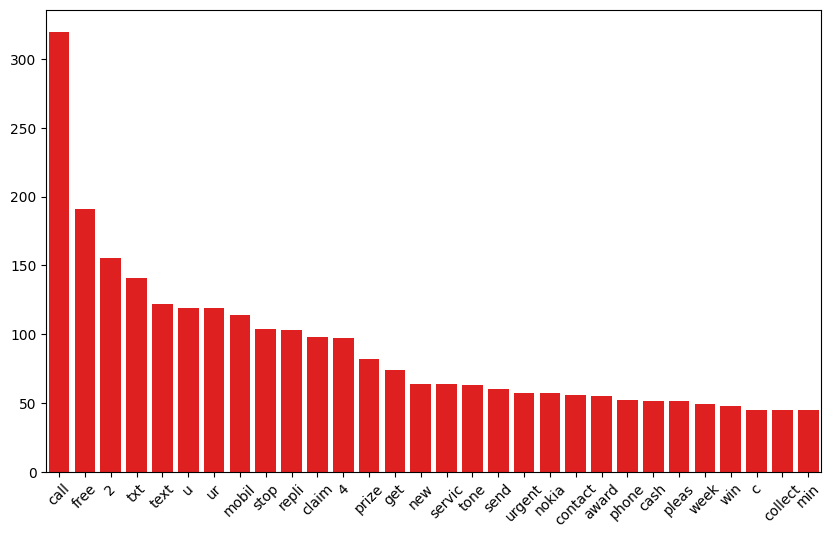

In [61]:
plt.figure(figsize=(10, 6))
sns.barplot(x=[x[0] for x in ss], y=[x[1] for x in ss], color="red")
# do xticks
plt.xticks(rotation=45)
plt.show()

In [62]:
import pandas as pd

data_pd = pd.Series([
    "I love machine learning",
    "I love Python",
    "Python is interesting"
])

In [63]:
result = data_pd.str.split()
result

0    [I, love, machine, learning]
1               [I, love, Python]
2       [Python, is, interesting]
dtype: object

In [64]:
print(result)

0    [I, love, machine, learning]
1               [I, love, Python]
2       [Python, is, interesting]
dtype: object


In [65]:
result = data_pd.str.split().explode()

print(result)

0              I
0           love
0        machine
0       learning
1              I
1           love
1         Python
2         Python
2             is
2    interesting
dtype: str


In [66]:

print(result.value_counts().head(3))

I         2
love      2
Python    2
Name: count, dtype: int64


In [67]:
store

transformed_text
call       320
free       191
2          155
txt        141
text       122
u          119
ur         119
mobil      114
stop       104
repli      103
claim       98
4           97
prize       82
get         74
new         64
servic      64
tone        63
send        60
urgent      57
nokia       57
contact     56
award       55
phone       52
cash        51
pleas       51
week        49
win         48
c           45
collect     45
min         45
Name: count, dtype: int64

In [68]:
data

,target,text,num_characters,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,1,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,0,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,0,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,0,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


### Model Building

In [69]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


tfidf = TfidfVectorizer()
cv = CountVectorizer()
# X = cv.fit_transform(data["transformed_text"]).toarray()
X = tfidf.fit_transform(data["transformed_text"]).toarray()

In [70]:
np.unique(X)

array([0.        , 0.03821809, 0.04407572, ..., 0.9786767 , 0.98003659,
       1.        ], shape=(35906,))

In [71]:
X.shape

(5169, 6708)

In [72]:
# vocabulary
# cv.vocabulary_
tfidf.vocabulary_

{'go': 2762,
 'jurong': 3393,
 'point': 4608,
 'crazi': 1806,
 'avail': 1017,
 'bugi': 1385,
 'great': 2835,
 'world': 6556,
 'la': 3497,
 'buffet': 1383,
 'cine': 1610,
 'got': 2801,
 'amor': 837,
 'wat': 6391,
 'ok': 4289,
 'lar': 3528,
 'joke': 3364,
 'wif': 6484,
 'oni': 4312,
 'free': 2610,
 'entri': 2291,
 'wkli': 6524,
 'comp': 1695,
 'win': 6494,
 'fa': 2404,
 'cup': 1855,
 'final': 2497,
 'tkt': 5987,
 '21st': 322,
 'may': 3839,
 'text': 5878,
 '87121': 609,
 'receiv': 4900,
 'question': 4819,
 'std': 5598,
 'txt': 6137,
 'rate': 4863,
 'appli': 906,
 '08452810075over18': 62,
 'dun': 2174,
 'say': 5139,
 'earli': 2190,
 'hor': 3059,
 'alreadi': 815,
 'nah': 4071,
 'think': 5925,
 'goe': 2768,
 'usf': 6246,
 'live': 3632,
 'around': 943,
 'though': 5940,
 'freemsg': 2617,
 'hey': 2995,
 'darl': 1900,
 'week': 6421,
 'word': 6550,
 'back': 1056,
 'like': 3602,
 'fun': 2657,
 'still': 5619,
 'tb': 5833,
 'xxx': 6612,
 'chg': 1569,
 'send': 5207,
 'rcv': 4873,
 'even': 2336,
 'bro

In [73]:
y = data["target"].values

In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [75]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [76]:
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)
accScore_gnb = accuracy_score(y_test, y_pred_gnb)
print(f"accuracy_score for the GaussianNB is {accScore_gnb}")
print(f"confusion matrix for the gnb is:  \n {confusion_matrix(y_test, y_pred_gnb)}")
print(f"precision_score for the gnb is {precision_score(y_test, y_pred_gnb)}")


accuracy_score for the GaussianNB is 0.8638824439288476
confusion matrix for the gnb is:  
 [[984 146]
 [ 30 133]]
precision_score for the gnb is 0.4767025089605735


In [77]:
mnb.fit(X_train, y_train)
y_pred_mnb = mnb.predict(X_test)

accScore_mnb = accuracy_score(y_test, y_pred_mnb)
print(f"accuracy_score for the MultinomialNB is {accScore_mnb}")
print(f"confusion matrix for the mnb is:  \n {confusion_matrix(y_test, y_pred_mnb)}")
print(f"precision_score for the mnb is {precision_score(y_test, y_pred_mnb)}")

accuracy_score for the MultinomialNB is 0.9535962877030162
confusion matrix for the mnb is:  
 [[1130    0]
 [  60  103]]
precision_score for the mnb is 1.0


In [78]:
bnb.fit(X_train, y_train)
y_pred_bnb = bnb.predict(X_test)

accScore_bnb = accuracy_score(y_test, y_pred_bnb)
print(f"accuracy_score for the BernoulliNB is {accScore_bnb}")
print(f"confusion matrix for the bnb is:  \n {confusion_matrix(y_test, y_pred_bnb)}")
print(f"precision_score for the bnb is {precision_score(y_test, y_pred_bnb)}")

accuracy_score for the BernoulliNB is 0.9690641918020109
confusion matrix for the bnb is:  
 [[1127    3]
 [  37  126]]
precision_score for the bnb is 0.9767441860465116


Choosing 
tf-idf -> MNB

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [80]:
svc = SVC()
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver="liblinear", penalty="l1")
rfc = RandomForestClassifier(n_estimators=50, random_state=42)
abc = AdaBoostClassifier(n_estimators=50, random_state=42)
bc = BaggingClassifier(n_estimators=50, random_state=42)
gbc = GradientBoostingClassifier(n_estimators=50, random_state=42)

In [81]:
clfs = {
    "svc": svc,
    "knc": knc,
    "mnb": mnb,
    "dtc": dtc,
    "lrc": lrc,
    "rfc": rfc,
    "abc": abc,
    "bc": bc,
    "gbc": gbc
}

In [82]:
performance = []

def model_fit_predict(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    accScore = accuracy_score(y_test, y_pred)
    precScore = precision_score(y_test, y_pred, zero_division=0)

    performance.append({
        "Algorithm_Name": clf.__class__.__name__,
        "Accuracy_Score": accScore,
        "Precision_Score": precScore
    })

    return accScore, precScore

In [83]:
accuracy = []
precision_scores = []

for name, clf in clfs.items():
    acc, prec = model_fit_predict(clf, X_train, y_train, X_test, y_test)

    accuracy.append(acc)
    precision_scores.append(prec)

print(accuracy)
print(precision_scores)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


[0.9667440061871616, 0.9010054137664346, 0.9535962877030162, 0.9373549883990719, 0.9559164733178654, 0.97138437741686, 0.9180201082753287, 0.9505027068832174, 0.9481825212683681]
[1.0, 1.0, 1.0, 0.8106060606060606, 0.9568965517241379, 0.9921875, 0.7614678899082569, 0.803680981595092, 0.9067796610169492]


In [84]:
print(accuracy.index(max(accuracy)))

5


In [85]:
performance

[{'Algorithm_Name': 'SVC',
  'Accuracy_Score': 0.9667440061871616,
  'Precision_Score': 1.0},
 {'Algorithm_Name': 'KNeighborsClassifier',
  'Accuracy_Score': 0.9010054137664346,
  'Precision_Score': 1.0},
 {'Algorithm_Name': 'MultinomialNB',
  'Accuracy_Score': 0.9535962877030162,
  'Precision_Score': 1.0},
 {'Algorithm_Name': 'DecisionTreeClassifier',
  'Accuracy_Score': 0.9373549883990719,
  'Precision_Score': 0.8106060606060606},
 {'Algorithm_Name': 'LogisticRegression',
  'Accuracy_Score': 0.9559164733178654,
  'Precision_Score': 0.9568965517241379},
 {'Algorithm_Name': 'RandomForestClassifier',
  'Accuracy_Score': 0.97138437741686,
  'Precision_Score': 0.9921875},
 {'Algorithm_Name': 'AdaBoostClassifier',
  'Accuracy_Score': 0.9180201082753287,
  'Precision_Score': 0.7614678899082569},
 {'Algorithm_Name': 'BaggingClassifier',
  'Accuracy_Score': 0.9505027068832174,
  'Precision_Score': 0.803680981595092},
 {'Algorithm_Name': 'GradientBoostingClassifier',
  'Accuracy_Score': 0.9481

In [86]:
df = pd.DataFrame(performance)

In [87]:
df

,Algorithm_Name,Accuracy_Score,Precision_Score
0,SVC,0.966744,1.000000
1,KNeighborsClassifier,0.901005,1.000000
2,MultinomialNB,0.953596,1.000000
3,DecisionTreeClassifier,0.937355,0.810606
4,LogisticRegression,0.955916,0.956897
5,RandomForestClassifier,0.971384,0.992188
6,AdaBoostClassifier,0.918020,0.761468
7,BaggingClassifier,0.950503,0.803681
8,GradientBoostingClassifier,0.948183,0.906780


In [88]:
df_melted = df.melt(
    id_vars="Algorithm_Name",
    value_vars=["Accuracy_Score", "Precision_Score"],
    var_name="variable",
    value_name="score"
)

In [89]:
df_melted

,Algorithm_Name,variable,score
0,SVC,Accuracy_Score,0.966744
1,KNeighborsClassifier,Accuracy_Score,0.901005
2,MultinomialNB,Accuracy_Score,0.953596
3,DecisionTreeClassifier,Accuracy_Score,0.937355
4,LogisticRegression,Accuracy_Score,0.955916
5,RandomForestClassifier,Accuracy_Score,0.971384
6,AdaBoostClassifier,Accuracy_Score,0.918020
7,BaggingClassifier,Accuracy_Score,0.950503
8,GradientBoostingClassifier,Accuracy_Score,0.948183
9,SVC,Precision_Score,1.000000


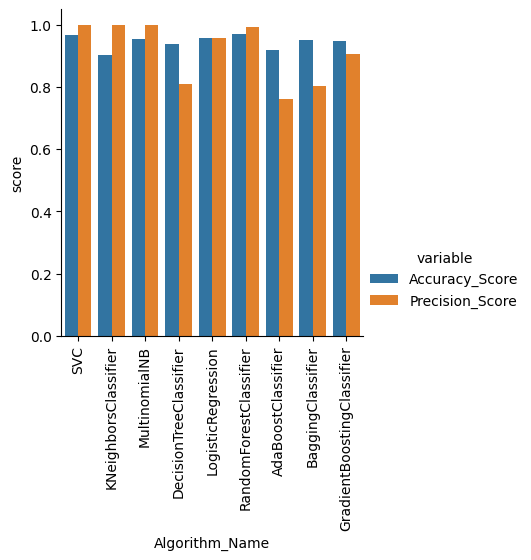

In [90]:
sns.catplot(
    x="Algorithm_Name",
    y="score",
    data=df_melted,
    hue="variable",
    kind="bar",
    height=4
)

plt.xticks(rotation="vertical")
plt.show()